# Bias Variance Trade-Off

In this notebook we are going to conduct a Bias-Variance Trade-off analysis. We are going to do this by implementing a ladder structure to explore our data to see what could have caused our model to not learn well on data that were bellow 500 to 999 reviews. 

Somewhat of the IDEA of LADDER:
1. Oregon, 3 grapes (Pinot Noir, Chardonnay, Pinot Gris) 
2. California, top 5 grapes
3. California, all grapes
4. All US
5. All Countries

In [12]:
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

df = pd.read_pickle("model_data.pkl")

# class_weight="balanced" / fit_prior=False stop the big grapes from drowning out the rare ones
# (Part 5 used class weights too, so this keeps the ladder comparable to the final model)
MODELS = {
    "M0 NB counts": make_pipeline(CountVectorizer(min_df=2, stop_words="english"), MultinomialNB(fit_prior=False)),
    "M1 LogReg unigrams": make_pipeline(TfidfVectorizer(min_df=2),
                                        LogisticRegression(max_iter=1000, class_weight="balanced")),
    "M2 LogReg 1-3 grams": make_pipeline(TfidfVectorizer(ngram_range=(1, 3), min_df=2, sublinear_tf=True),
                                         LogisticRegression(max_iter=1000, class_weight="balanced")),
}

LADDER = {
    "1 Oregon, 3 grapes": (df.province == "Oregon") & df.grape.isin(["Pinot Noir", "Chardonnay", "Pinot Gris"]),
    "2 California, top 5": (df.province == "California") & df.grape.isin(
                               df[df.province == "California"].grape.value_counts().index[:5]),
    "3 California, all": df.province == "California",
    "4 US": df.country == "US",
    "5 All countries": df.country.notna(),
}

def run_step(rung, model_name, min_per_class=30, models=MODELS):
    part = df[LADDER[rung]]
    counts = part.grape.value_counts()
    part = part[part.grape.isin(counts[counts >= min_per_class].index)] # drop classes too small to learn
    tr, va = part[part.split == "train"], part[part.split == "val"]

    model = clone(models[model_name]).fit(tr.description_masked, tr.grape)
    train_f1 = f1_score(tr.grape, model.predict(tr.description_masked), average="macro")
    val_f1   = f1_score(va.grape, model.predict(va.description_masked), average="macro")
    return {"rung": rung, "model": model_name, "n_train": len(tr), "n_classes": part.grape.nunique(),
            "train_f1": train_f1, "val_f1": val_f1, "gap": train_f1 - val_f1}


In [13]:
def diagnose(r, gap_tol=0.10, good_train=0.85):
    if r["train_f1"] < good_train and r["gap"] <= gap_tol:
        return "underfit -> more complex model / more features"
    if r["gap"] > gap_tol:
        return "overfit -> add data (next rung) or regularize"
    return "balanced"


log = []
for rung in LADDER:
    for name in MODELS:
        r = run_step(rung, name)
        r["diagnosis"] = diagnose(r)
        log.append(r)
        print(f"{rung:22} {name:20} train {r['train_f1']:.3f}  val {r['val_f1']:.3f}  gap {r['gap']:.3f}  {r['diagnosis']}")

pd.DataFrame(log).round(3)


1 Oregon, 3 grapes     M0 NB counts         train 0.921  val 0.850  gap 0.072  balanced
1 Oregon, 3 grapes     M1 LogReg unigrams   train 0.973  val 0.839  gap 0.134  overfit -> add data (next rung) or regularize
1 Oregon, 3 grapes     M2 LogReg 1-3 grams  train 0.993  val 0.806  gap 0.187  overfit -> add data (next rung) or regularize
2 California, top 5    M0 NB counts         train 0.790  val 0.724  gap 0.067  underfit -> more complex model / more features
2 California, top 5    M1 LogReg unigrams   train 0.852  val 0.754  gap 0.098  balanced
2 California, top 5    M2 LogReg 1-3 grams  train 0.939  val 0.760  gap 0.179  overfit -> add data (next rung) or regularize
3 California, all      M0 NB counts         train 0.349  val 0.204  gap 0.145  overfit -> add data (next rung) or regularize
3 California, all      M1 LogReg unigrams   train 0.661  val 0.331  gap 0.330  overfit -> add data (next rung) or regularize
3 California, all      M2 LogReg 1-3 grams  train 0.853  val 0.333  gap 0

,rung,model,n_train,n_classes,train_f1,val_f1,gap,diagnosis
0,"1 Oregon, 3 grapes",M0 NB counts,3038,3,0.921,0.850,0.072,balanced
1,"1 Oregon, 3 grapes",M1 LogReg unigrams,3038,3,0.973,0.839,0.134,overfit -> add data (next rung) or regularize
2,"1 Oregon, 3 grapes",M2 LogReg 1-3 grams,3038,3,0.993,0.806,0.187,overfit -> add data (next rung) or regularize
3,"2 California, top 5",M0 NB counts,21153,5,0.790,0.724,0.067,underfit -> more complex model / more features
4,"2 California, top 5",M1 LogReg unigrams,21153,5,0.852,0.754,0.098,balanced
5,"2 California, top 5",M2 LogReg 1-3 grams,21153,5,0.939,0.760,0.179,overfit -> add data (next rung) or regularize
6,"3 California, all",M0 NB counts,28112,23,0.349,0.204,0.145,overfit -> add data (next rung) or regularize
7,"3 California, all",M1 LogReg unigrams,28112,23,0.661,0.331,0.330,overfit -> add data (next rung) or regularize
8,"3 California, all",M2 LogReg 1-3 grams,28112,23,0.853,0.333,0.520,overfit -> add data (next rung) or regularize
9,4 US,M0 NB counts,40045,25,0.358,0.231,0.127,overfit -> add data (next rung) or regularize


In [14]:
# Regularization sweep on the rung where M2 overfit the most (Oregon, 3 grapes).
# Kept in its own dict so it doesn't get mixed into MODELS and the ladder plots.
C_SWEEP = {
    f"M2 C={C}": make_pipeline(TfidfVectorizer(ngram_range=(1, 3), min_df=2, sublinear_tf=True),
                               LogisticRegression(C=C, max_iter=1000, class_weight="balanced"))
    for C in [0.01, 0.1, 1, 10]
}

sweep = pd.DataFrame([run_step("1 Oregon, 3 grapes", name, models=C_SWEEP) for name in C_SWEEP])
sweep.round(3)


,rung,model,n_train,n_classes,train_f1,val_f1,gap
0,"1 Oregon, 3 grapes",M2 C=0.01,3038,3,0.936,0.823,0.113
1,"1 Oregon, 3 grapes",M2 C=0.1,3038,3,0.958,0.822,0.136
2,"1 Oregon, 3 grapes",M2 C=1,3038,3,0.993,0.806,0.187
3,"1 Oregon, 3 grapes",M2 C=10,3038,3,1.000,0.813,0.187


In [15]:
EUROPE = ["France", "Italy", "Spain", "Portugal", "Germany", "Austria"]
shared = set(df[df.country == "US"].grape) & set(df[df.country.isin(EUROPE)].grape)

train_us = df[(df.country == "US") & (df.split == "train") & df.grape.isin(shared)]
model = clone(MODELS["M2 LogReg 1-3 grams"]).fit(train_us.description_masked, train_us.grape)

for label, mask in [("US (same region)", df.country == "US"), ("Europe (new region)", df.country.isin(EUROPE))]:
    te = df[mask & (df.split == "test") & df.grape.isin(shared)]
    print(f"{label:20} macro F1 {f1_score(te.grape, model.predict(te.description_masked), average='macro'):.3f}  (n={len(te):,})")


US (same region)     macro F1 0.301  (n=8,431)
Europe (new region)  macro F1 0.115  (n=5,150)


In [16]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

INK, INK_2, MUTED, SURFACE = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
STYLE = {
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "legend.frameon": False,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
}
LADDER_COLORS = {"M0 NB counts": "#1baf7a", "M1 LogReg unigrams": "#2a78d6", "M2 LogReg 1-3 grams": "#eb6834"}
PLOT_MODELS = list(LADDER_COLORS)   # only the ladder models, never the C-sweep ones

log_df = pd.DataFrame(log)
rungs = list(LADDER)
short = [r.split(" ", 1)[1] for r in rungs]          # "1 Oregon, 3 grapes" -> "Oregon, 3 grapes"
x = np.arange(len(rungs))

def model_rows(name):
    return log_df[log_df.model == name].set_index("rung").loc[rungs]   # one model, in ladder order


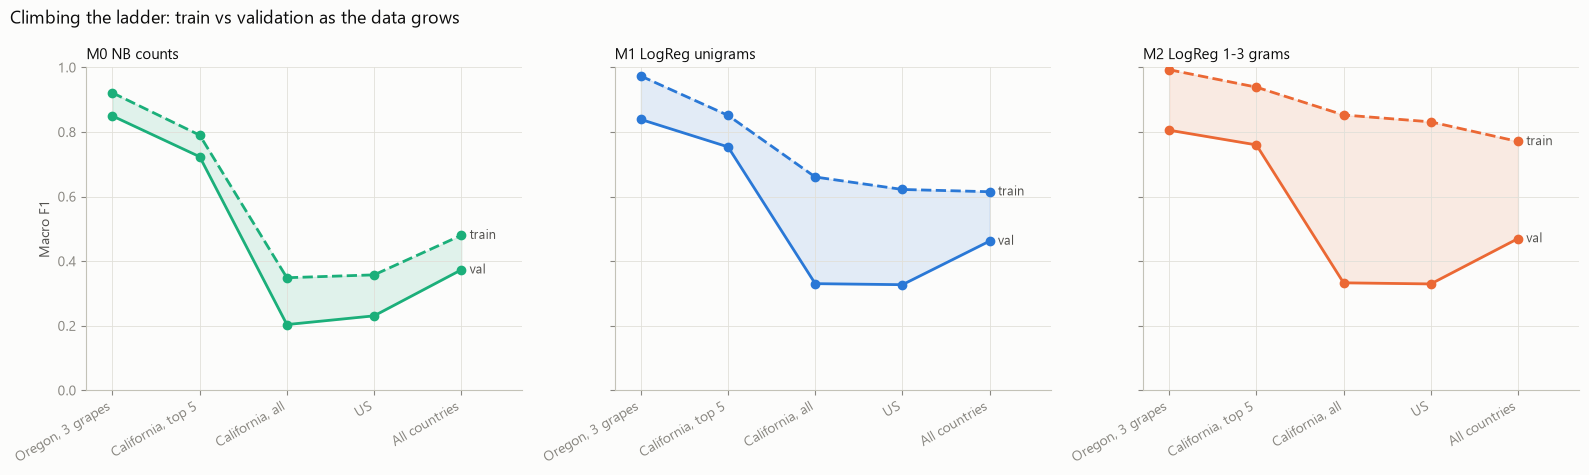

In [17]:
with plt.rc_context(STYLE):
    fig, axes = plt.subplots(1, len(PLOT_MODELS), figsize=(16, 4.8), sharey=True)
    for ax, name in zip(axes, PLOT_MODELS):
        sub, c = model_rows(name), LADDER_COLORS[name]
        ax.plot(x, sub.train_f1, color=c, linestyle="--", marker="o", markersize=6)
        ax.plot(x, sub.val_f1, color=c, marker="o", markersize=6)
        ax.fill_between(x, sub.val_f1, sub.train_f1, color=c, alpha=0.12)     # shaded gap = variance
        ax.annotate("train", (x[-1], sub.train_f1.iloc[-1]), xytext=(6, 0), textcoords="offset points",
                    va="center", color=INK_2, fontsize=9)
        ax.annotate("val", (x[-1], sub.val_f1.iloc[-1]), xytext=(6, 0), textcoords="offset points",
                    va="center", color=INK_2, fontsize=9)
        ax.set_xticks(x, short, rotation=30, ha="right")
        ax.set_xlim(-0.3, len(rungs) - 1 + 0.7)
        ax.set_title(name, loc="left", fontsize=11)
    axes[0].set_ylim(0, 1)
    axes[0].set_ylabel("Macro F1")
    fig.suptitle("Climbing the ladder: train vs validation as the data grows", x=0.01, ha="left", fontsize=13)
    fig.tight_layout()
    plt.show()


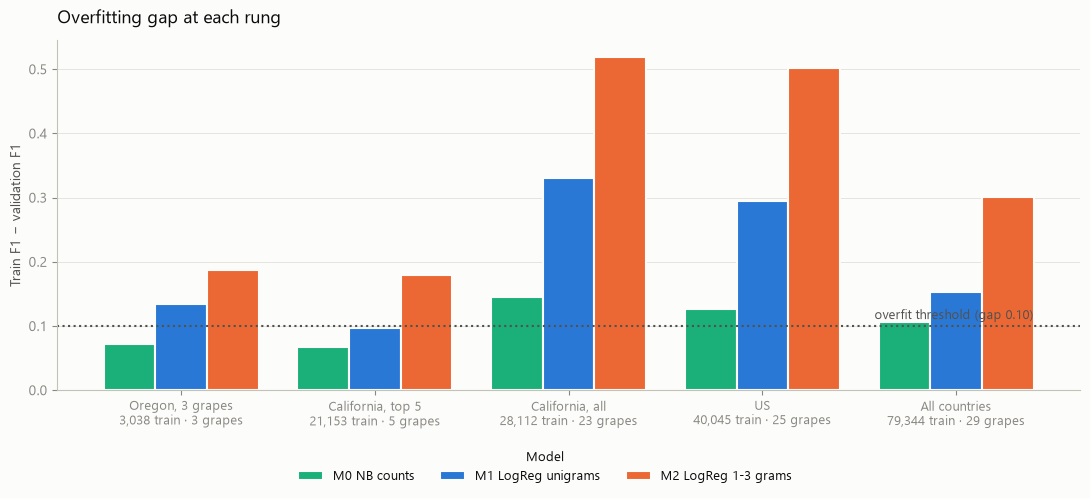

In [18]:
n_info = log_df.drop_duplicates("rung").set_index("rung").loc[rungs]
bar_w = 0.8 / len(PLOT_MODELS)

with plt.rc_context(STYLE):
    fig, ax = plt.subplots(figsize=(11, 5))
    for k, name in enumerate(PLOT_MODELS):
        ax.bar(x + (k - (len(PLOT_MODELS) - 1) / 2) * bar_w, model_rows(name).gap, width=bar_w,
               color=LADDER_COLORS[name], edgecolor=SURFACE, linewidth=1.5, label=name)
    ax.axhline(0.10, color=INK_2, linestyle=":", linewidth=1.5)
    ax.annotate("overfit threshold (gap 0.10)", (len(rungs) - 0.6, 0.10), xytext=(0, 5),
                textcoords="offset points", ha="right", color=INK_2, fontsize=9)
    ax.set_xticks(x, [f"{s}\n{t:,} train · {c} grapes" for s, t, c in zip(short, n_info.n_train, n_info.n_classes)],
                  fontsize=9)
    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)
    ax.set_ylabel("Train F1 − validation F1")
    ax.set_title("Overfitting gap at each rung", loc="left", fontsize=13, pad=12)
    fig.legend(*ax.get_legend_handles_labels(), title="Model", loc="lower center",
               bbox_to_anchor=(0.5, 0), ncol=len(PLOT_MODELS), fontsize=9, title_fontsize=9)
    fig.tight_layout(rect=(0, 0.1, 1, 1))
    plt.show()


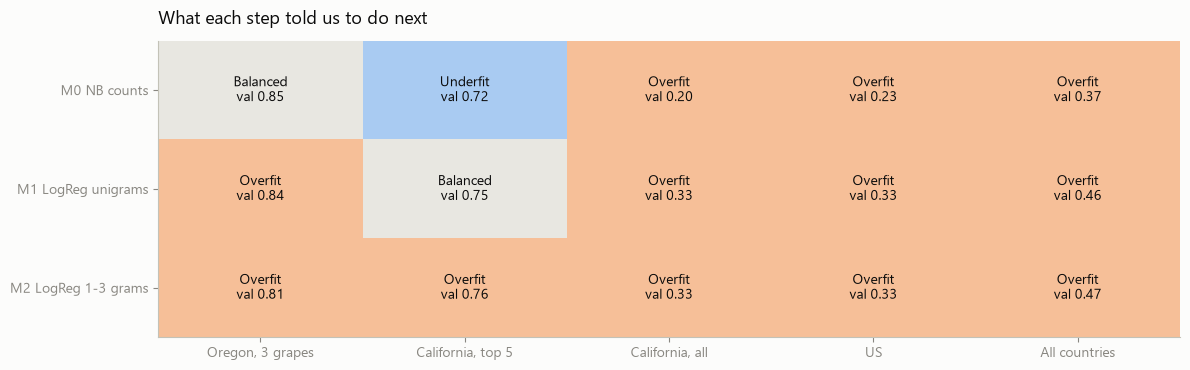

In [19]:
LABELS = {"under": "Underfit", "balan": "Balanced", "overf": "Overfit"}
CODE = {"Underfit": 0, "Balanced": 1, "Overfit": 2}

diag = log_df.assign(label=log_df.diagnosis.str[:5].map(LABELS))
grid = diag.pivot(index="model", columns="rung", values="label").loc[PLOT_MODELS, rungs]
vals = diag.pivot(index="model", columns="rung", values="val_f1").loc[PLOT_MODELS, rungs]

with plt.rc_context(STYLE):
    fig, ax = plt.subplots(figsize=(12, 3.8))
    ax.imshow(grid.replace(CODE).astype(int).to_numpy(), aspect="auto", vmin=0, vmax=2,
              cmap=ListedColormap(["#a9cbf2", "#e8e7e1", "#f6bf98"]))      # blue = underfit, orange = overfit
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            ax.text(j, i, f"{grid.iat[i, j]}\nval {vals.iat[i, j]:.2f}", ha="center", va="center",
                    fontsize=10, color=INK)
    ax.set_xticks(range(len(rungs)), short)
    ax.set_yticks(range(len(PLOT_MODELS)), PLOT_MODELS)
    ax.grid(False)
    ax.set_title("What each step told us to do next", loc="left", fontsize=13, pad=12)
    fig.tight_layout()
    plt.show()
